# 08 - pandas

**Sources:** Summer School *CursP_sklearn* (section "pandas": fast `DataFrame`, I/O for CSV/Excel/SQL/HDF5,
missing data, alignment, merging) and Bootcamp BP5 ("Data Manipulation and Analysis Libraries: NumPy, pandas,
SciPy" - heading only).

**Modern notes:** the slides show `Panel` and `scikits.timeseries` - both are **gone** (`Panel` was removed in
pandas 0.25; use a `MultiIndex` DataFrame or `xarray`). In pandas 3 the default string dtype is `str`, and
**Copy-on-Write** is always on (so avoid chained assignment like `df[df.a > 0]["b"] = 1`).

**Contents:** Series -> DataFrame -> selection (`loc`/`iloc`/boolean) -> missing data -> column operations ->
groupby/aggregation -> merge/join/concat -> time series -> reshaping -> I/O -> plotting -> good habits.

In [1]:
import numpy as np
import pandas as pd

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 20)
print(pd.__version__)

3.0.6


## 1. Series - a labelled 1-D array

In [2]:
s = pd.Series(np.random.default_rng(0).normal(size=5), index=list("abcde"))
print(s)
print(s["a"], s.iloc[0], s[["a", "c"]].values, s.index.tolist(), s.dtype)
print(s * 2, s[s > 0], s.mean(), sep="\n")

# From a dict: index = keys; arithmetic aligns on labels
a = pd.Series({"x": 1, "y": 2, "z": 3})
b = pd.Series({"y": 10, "z": 20, "w": 30})
print(a + b)                       # NaN where a label exists in only one Series
print(a.add(b, fill_value=0))

a    0.126
b   -0.132
c    0.640
d    0.105
e   -0.536
dtype: float64
0.1257302210933933 0.1257302210933933 [0.12573022 0.64042265] ['a', 'b', 'c', 'd', 'e'] float64
a    0.251
b   -0.264
c    1.281
d    0.210
e   -1.071
dtype: float64
a    0.126
c    0.640
d    0.105
dtype: float64
0.040655750447460434
w     NaN
x     NaN
y    12.0
z    23.0
dtype: float64
w    30.0
x     1.0
y    12.0
z    23.0
dtype: float64


## 2. DataFrame - a table of labelled columns
Think "dict of Series sharing an index", or an Excel sheet / SQL table.

In [3]:
dates = pd.date_range("2000-01-01", periods=8)
df = pd.DataFrame(np.random.default_rng(1).normal(size=(8, 3)), index=dates, columns=["A", "B", "C"])
print(df)
print(df.shape, df.dtypes.tolist(), df.index[:2].tolist(), list(df.columns))
print(df.head(3), df.tail(2), df.describe(), sep="\n")
df.info()

                A      B      C
2000-01-01  0.346  0.822  0.330
2000-01-02 -1.303  0.905  0.446
2000-01-03 -0.537  0.581  0.365
2000-01-04  0.294  0.028  0.547
2000-01-05 -0.736 -0.163 -0.482
2000-01-06  0.599  0.040 -0.292
2000-01-07 -0.782 -0.257  0.008
2000-01-08 -0.276  1.294  1.007
(8, 3) [dtype('float64'), dtype('float64'), dtype('float64')] [Timestamp('2000-01-01 00:00:00'), Timestamp('2000-01-02 00:00:00')] ['A', 'B', 'C']
                A      B      C
2000-01-01  0.346  0.822  0.330
2000-01-02 -1.303  0.905  0.446
2000-01-03 -0.537  0.581  0.365
                A      B      C
2000-01-07 -0.782 -0.257  0.008
2000-01-08 -0.276  1.294  1.007
           A      B      C
count  8.000  8.000  8.000
mean  -0.299  0.406  0.241
std    0.662  0.571  0.479
min   -1.303 -0.257 -0.482
25%   -0.748 -0.019 -0.067
50%   -0.406  0.310  0.348
75%    0.307  0.843  0.471
max    0.599  1.294  1.007
<class 'pandas.DataFrame'>
DatetimeIndex: 8 entries, 2000-01-01 to 2000-01-08
Freq: D
Data columns

In [4]:
people = pd.DataFrame({
    "name": ["Ana", "Bob", "Cy", "Dee", "Eli", "Fay"],
    "city": ["Madrid", "Lyon", "Madrid", "Lyon", "Oslo", "Oslo"],
    "age": [31, 25, 40, np.nan, 29, 52],
    "salary": [52_000, 41_000, 67_000, 38_000, 45_000, 80_000],
    "joined": pd.to_datetime(["2019-03-01", "2021-07-15", "2015-01-10", "2022-11-30", "2020-05-05", "2012-09-17"]),
})
print(people)
print(people.dtypes)

  name    city   age  salary     joined
0  Ana  Madrid  31.0   52000 2019-03-01
1  Bob    Lyon  25.0   41000 2021-07-15
2   Cy  Madrid  40.0   67000 2015-01-10
3  Dee    Lyon   NaN   38000 2022-11-30
4  Eli    Oslo  29.0   45000 2020-05-05
5  Fay    Oslo  52.0   80000 2012-09-17
name                 str
city                 str
age              float64
salary             int64
joined    datetime64[us]
dtype: object


## 3. Selecting data
* `df["col"]` -> Series; `df[["c1", "c2"]]` -> DataFrame
* `df.loc[rows, cols]` -> **label**-based (end inclusive)
* `df.iloc[rows, cols]` -> **position**-based (end exclusive, like Python slicing)
* boolean masks (`&`, `|`, `~` with parentheses) and `.query("...")`

In [5]:
print(people["name"].tolist())
print(people[["name", "salary"]].head(2))
print(people.loc[1:3, "name":"age"])           # label slice: INCLUDES 3
print(people.iloc[1:3, 0:2])                   # position slice: excludes 3
print(people.loc[people["salary"] > 50_000, ["name", "salary"]])
print(people[(people.city == "Lyon") | (people.age > 50)])
print(people.query("city == 'Oslo' and salary > 50000"))
print(people[people["city"].isin(["Oslo", "Madrid"])].shape)

['Ana', 'Bob', 'Cy', 'Dee', 'Eli', 'Fay']
  name  salary
0  Ana   52000
1  Bob   41000
  name    city   age
1  Bob    Lyon  25.0
2   Cy  Madrid  40.0
3  Dee    Lyon   NaN
  name    city
1  Bob    Lyon
2   Cy  Madrid
  name  salary
0  Ana   52000
2   Cy   67000
5  Fay   80000
  name  city   age  salary     joined
1  Bob  Lyon  25.0   41000 2021-07-15
3  Dee  Lyon   NaN   38000 2022-11-30
5  Fay  Oslo  52.0   80000 2012-09-17
  name  city   age  salary     joined
5  Fay  Oslo  52.0   80000 2012-09-17
(4, 5)


In [6]:
# Setting values: use .loc (never chained indexing)
people2 = people.copy()
people2.loc[people2["name"] == "Dee", "age"] = 35
people2["senior"] = people2["age"] >= 40
people2["salary_k"] = people2["salary"] / 1000
print(people2[["name", "age", "senior", "salary_k"]])

  name   age  senior  salary_k
0  Ana  31.0   False      52.0
1  Bob  25.0   False      41.0
2   Cy  40.0    True      67.0
3  Dee  35.0   False      38.0
4  Eli  29.0   False      45.0
5  Fay  52.0    True      80.0


## 4. Missing data
`NaN` (float) / `NaT` (datetime) / `pd.NA`. Most reductions skip NaN; arithmetic propagates it.

In [7]:
df_na = pd.DataFrame({"one": [2.2, 0.1, 0.0, np.nan], "three": [np.nan, 0.64, 0.70, 0.33], "two": [-1.4, -1.1, 0.84, -0.43]},
                     index=list("abcd"))
print(df_na)
print(df_na.mean(axis=0))                  # per column (skips NaN) - as in the slides: df.mean(0)
print(df_na.isna().sum(), df_na.dropna(), df_na.fillna(0), df_na.fillna(df_na.mean()), sep="\n")
print(df_na.interpolate())

   one  three   two
a  2.2    NaN -1.40
b  0.1   0.64 -1.10
c  0.0   0.70  0.84
d  NaN   0.33 -0.43
one      0.767
three    0.557
two     -0.523
dtype: float64
one      1
three    1
two      0
dtype: int64
   one  three   two
b  0.1   0.64 -1.10
c  0.0   0.70  0.84
   one  three   two
a  2.2   0.00 -1.40
b  0.1   0.64 -1.10
c  0.0   0.70  0.84
d  0.0   0.33 -0.43
     one  three   two
a  2.200  0.557 -1.40
b  0.100  0.640 -1.10
c  0.000  0.700  0.84
d  0.767  0.330 -0.43
   one  three   two
a  2.2    NaN -1.40
b  0.1   0.64 -1.10
c  0.0   0.70  0.84
d  0.0   0.33 -0.43


## 5. Operations on columns, `apply`, `map`, strings, dates

In [8]:
p = people.copy()
p["age"] = p["age"].fillna(p["age"].median())
p["tenure_years"] = (pd.Timestamp("2026-10-09") - p["joined"]).dt.days / 365.25
p["name_upper"] = p["name"].str.upper()
p["initial"] = p["name"].str[0]
p["salary_band"] = pd.cut(p["salary"], bins=[0, 45_000, 60_000, np.inf], labels=["low", "mid", "high"])
p["city_code"] = p["city"].map({"Madrid": "MAD", "Lyon": "LYS", "Oslo": "OSL"})
p["bonus"] = p.apply(lambda row: row["salary"] * (0.1 if row["tenure_years"] > 5 else 0.05), axis=1)
print(p[["name", "age", "tenure_years", "salary_band", "city_code", "bonus"]])
print(p["joined"].dt.year.tolist(), p["joined"].dt.day_name().tolist()[:3])
print(p["salary"].rank(ascending=False).tolist(), p.nlargest(2, "salary")["name"].tolist(), p["city"].value_counts().to_dict())

  name   age  tenure_years salary_band city_code   bonus
0  Ana  31.0         7.608         mid       MAD  5200.0
1  Bob  25.0         5.235         low       LYS  4100.0
2   Cy  40.0        11.745        high       MAD  6700.0
3  Dee  31.0         3.858         low       LYS  1900.0
4  Eli  29.0         6.428         low       OSL  4500.0
5  Fay  52.0        14.059        high       OSL  8000.0
[2019, 2021, 2015, 2022, 2020, 2012] ['Friday', 'Thursday', 'Saturday']
[3.0, 5.0, 2.0, 6.0, 4.0, 1.0] ['Fay', 'Cy'] {'Madrid': 2, 'Lyon': 2, 'Oslo': 2}


## 6. Group-by: split -> apply -> combine

In [9]:
g = people.groupby("city")
print(g["salary"].mean())
print(g.agg(n=("name", "count"), mean_salary=("salary", "mean"), max_age=("age", "max")))
print(g["salary"].transform(lambda x: x - x.mean()).tolist())   # keeps original shape
print(people.groupby(["city", people["joined"].dt.year >= 2020])["salary"].median())

city
Lyon      39500.0
Madrid    59500.0
Oslo      62500.0
Name: salary, dtype: float64
        n  mean_salary  max_age
city                           
Lyon    2      39500.0     25.0
Madrid  2      59500.0     40.0
Oslo    2      62500.0     52.0
[-7500.0, 1500.0, 7500.0, -1500.0, -17500.0, 17500.0]
city    joined
Lyon    True      39500.0
Madrid  False     59500.0
Oslo    False     80000.0
        True      45000.0
Name: salary, dtype: float64


In [10]:
# Pivot tables and cross-tabs
people["recent"] = people["joined"].dt.year >= 2020
print(people.pivot_table(index="city", columns="recent", values="salary", aggfunc="mean"))
print(pd.crosstab(people["city"], people["recent"]))

recent    False    True 
city                    
Lyon        NaN  39500.0
Madrid  59500.0      NaN
Oslo    80000.0  45000.0


recent  False  True 
city                
Lyon        0      2
Madrid      2      0
Oslo        1      1


## 7. Combining tables: `concat`, `merge` (SQL-style joins)

In [11]:
cities = pd.DataFrame({"city": ["Madrid", "Lyon", "Paris"], "country": ["ES", "FR", "FR"]})
print(people[["name", "city"]].merge(cities, on="city", how="left"))      # keep all people
print(people[["name", "city"]].merge(cities, on="city", how="inner"))     # only matching rows
print(people[["name", "city"]].merge(cities, on="city", how="outer"))     # everything

print(pd.concat([people.head(2), people.tail(2)], ignore_index=True)[["name"]])
print(pd.concat([people["name"], people["age"]], axis=1).head(2))

  name    city country
0  Ana  Madrid      ES
1  Bob    Lyon      FR
2   Cy  Madrid      ES
3  Dee    Lyon      FR
4  Eli    Oslo     NaN
5  Fay    Oslo     NaN
  name    city country
0  Ana  Madrid      ES
1  Bob    Lyon      FR
2   Cy  Madrid      ES
3  Dee    Lyon      FR
  name    city country
0  Bob    Lyon      FR
1  Dee    Lyon      FR
2  Ana  Madrid      ES
3   Cy  Madrid      ES
4  Eli    Oslo     NaN
5  Fay    Oslo     NaN
6  NaN   Paris      FR
  name
0  Ana
1  Bob
2  Eli
3  Fay
  name   age
0  Ana  31.0
1  Bob  25.0


## 8. Time series
`DatetimeIndex` gives partial-string slicing, `resample` (like group-by on time), `rolling` windows, `shift`, `diff`.

In [12]:
idx = pd.date_range("2024-01-01", periods=120, freq="D")
ts = pd.Series(np.random.default_rng(2).normal(0, 1, 120).cumsum(), index=idx, name="price")
print(ts["2024-02"].head(3))
print(ts.resample("MS").agg(["mean", "min", "max"]))        # month-start buckets
print(ts.rolling(7).mean().tail(3))                          # 7-day moving average
print(ts.diff().head(3), ts.shift(1).head(3), ts.pct_change().abs().idxmax(), sep="\n")

2024-02-01   -1.297
2024-02-02   -0.219
2024-02-03    0.504
Freq: D, Name: price, dtype: float64
             mean    min    max
2024-01-01 -0.165 -3.188  2.606
2024-02-01  1.554 -1.297  5.820
2024-03-01  2.983  0.555  5.585
2024-04-01  1.232 -2.675  3.473
2024-04-27    1.746
2024-04-28    1.832
2024-04-29    1.874
Freq: D, Name: price, dtype: float64
2024-01-01      NaN
2024-01-02   -0.523
2024-01-03   -0.413
Freq: D, Name: price, dtype: float64
2024-01-01      NaN
2024-01-02    0.189
2024-01-03   -0.334
Freq: D, Name: price, dtype: float64
2024-04-09 00:00:00


## 9. Reshaping: wide <-> long

In [13]:
wide = pd.DataFrame({"id": [1, 2], "math": [9, 7], "art": [6, 8]})
long = wide.melt(id_vars="id", var_name="subject", value_name="grade")
print(long)
print(long.pivot(index="id", columns="subject", values="grade"))
print(people.set_index("name").loc[["Ana", "Fay"], ["salary"]])

   id subject  grade
0   1    math      9
1   2    math      7
2   1     art      6
3   2     art      8
subject  art  math
id                
1          6     9
2          8     7
      salary
name        
Ana    52000
Fay    80000


## 10. Reading and writing data
`pd.read_csv / to_csv`, `read_excel` (needs `openpyxl`), `read_json`, `read_sql`, `read_parquet`
(needs `pyarrow`), `read_hdf` (needs `tables`). We use in-memory text so the notebook is self-contained.

In [14]:
import io

csv_text = """id;name;score;date
1;ana;9,5;2024-01-03
2;bob;;2024-01-04
3;cy;7,25;not-a-date
"""
tidy = pd.read_csv(io.StringIO(csv_text), sep=";", decimal=",", index_col="id")
print(tidy)
print(tidy.dtypes)
tidy["date"] = pd.to_datetime(tidy["date"], errors="coerce")     # invalid -> NaT
print(tidy)

buf = io.StringIO()
people.to_csv(buf, index=False)
print(buf.getvalue()[:120])
print(people.to_json(orient="records")[:100])

   name  score        date
id                        
1   ana   9.50  2024-01-03
2   bob    NaN  2024-01-04
3    cy   7.25  not-a-date
name         str
score    float64
date         str
dtype: object
   name  score       date
id                       
1   ana   9.50 2024-01-03
2   bob    NaN 2024-01-04
3    cy   7.25        NaT
name,city,age,salary,joined,recent
Ana,Madrid,31.0,52000,2019-03-01,False
Bob,Lyon,25.0,41000,2021-07-15,True
Cy,Madr
[{"name":"Ana","city":"Madrid","age":31.0,"salary":52000,"joined":1551398400000,"recent":false},{"na


C:\Users\leire\AppData\Local\Temp\ipykernel_13536\509830652.py:17: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  print(people.to_json(orient="records")[:100])


## 11. Plotting straight from pandas (Matplotlib under the hood)

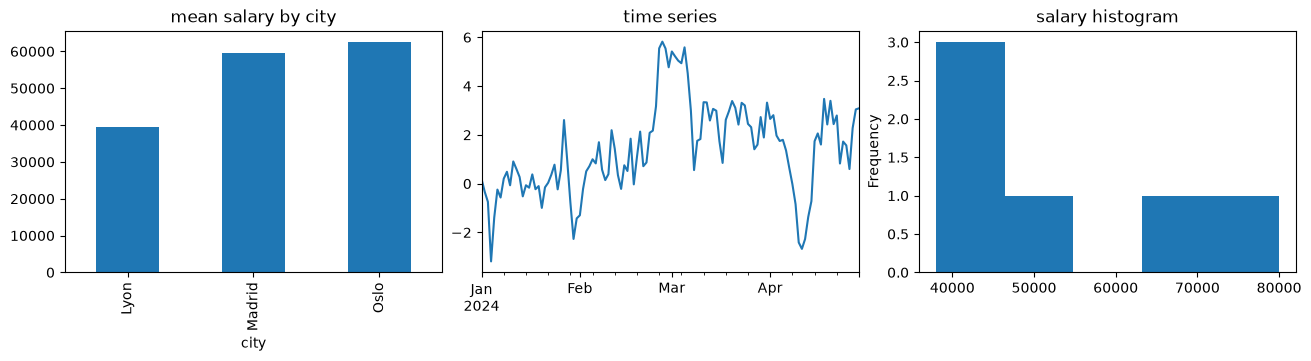

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), constrained_layout=True)
people.groupby("city")["salary"].mean().plot.bar(ax=axes[0], title="mean salary by city")
ts.plot(ax=axes[1], title="time series")
people["salary"].plot.hist(ax=axes[2], bins=5, title="salary histogram")
plt.show()

            sepal length (cm)  sepal width (cm)  petal length (cm)  \
species                                                              
setosa                  5.006             3.428              1.462   
versicolor              5.936             2.770              4.260   
virginica               6.588             2.974              5.552   

            petal width (cm)  target  
species                               
setosa                 0.246     0.0  
versicolor             1.326     1.0  
virginica              2.026     2.0  


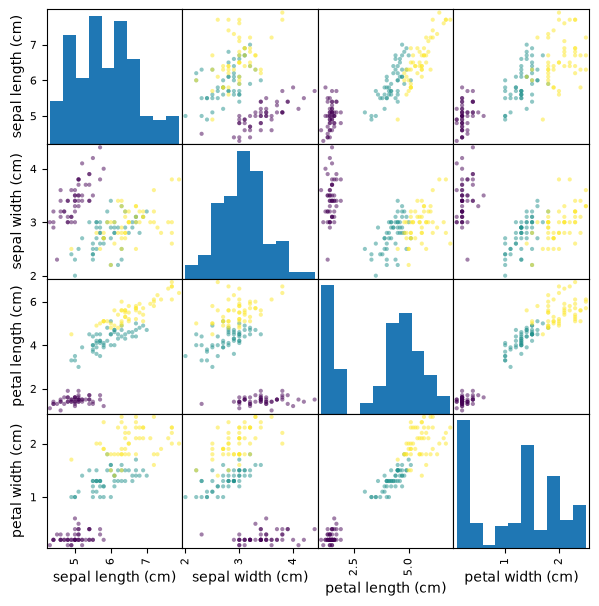

In [16]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
iris_df = iris.frame.assign(species=lambda d: d["target"].map(dict(enumerate(iris.target_names))))
print(iris_df.groupby("species").mean(numeric_only=True))
pd.plotting.scatter_matrix(iris_df.iloc[:, :4], c=iris_df["target"], figsize=(7, 7), diagonal="hist")
plt.show()

## 12. Good habits
* Prefer **vectorised** column operations to `apply(axis=1)` / row loops (`iterrows` is very slow).
* Use `.loc[mask, col] = value`; avoid chained indexing; call `.copy()` when you want an independent table.
* Check types early (`df.dtypes`, `df.info()`), convert (`astype`, `pd.to_numeric`, `pd.to_datetime`, `category`).
* Keep raw data immutable; do cleaning in a *pipeline* of functions: `df.pipe(clean).pipe(add_features)`.
* Use `assert`/small tests on shapes and invariants (no duplicates in an id, no NaN in keys).

In [17]:
def clean(d):
    return d.assign(city=d["city"].str.strip().str.title()).drop_duplicates("name")

def add_features(d):
    return d.assign(salary_k=d["salary"] / 1000)

result = people.pipe(clean).pipe(add_features)
assert result["name"].is_unique and result["salary_k"].between(0, 1000).all()
print(result[["name", "city", "salary_k"]].head(3))

  name    city  salary_k
0  Ana  Madrid      52.0
1  Bob    Lyon      41.0
2   Cy  Madrid      67.0


In [18]:
# Speed: vectorised vs apply
import timeit
big = pd.DataFrame({"a": np.arange(200_000), "b": np.arange(200_000) * 2.0})
t_vec = timeit.timeit(lambda: big["a"] * big["b"], number=5) / 5
t_apply = timeit.timeit(lambda: big.apply(lambda r: r["a"] * r["b"], axis=1), number=1)
print(f"vectorised {t_vec * 1e3:.2f} ms | apply(axis=1) {t_apply * 1e3:.0f} ms")

vectorised 0.83 ms | apply(axis=1) 677 ms


## Exercises

**A. Explore the diabetes dataset** (`sklearn.datasets.load_diabetes(as_frame=True)`): show missing values, summary
statistics, the correlation matrix (`df.corr()`) as a heat-map, and the 3 features most correlated with the target.

**B. Cleaning drill.** Build a messy DataFrame (mixed-case cities with spaces, numbers as strings with commas,
duplicated rows, missing values, dates in two formats) and write a `clean()` function with tests.

**C. Group-by questions.** From a sales table (invent one with 1 000 random rows: date, store, product, units, price)
answer: revenue per store per month, top-3 products per store, month-over-month growth.

**D. Re-implement `groupby().mean()`** with only dicts and lists, then compare speed with pandas on 1 M rows.

In [19]:
# Your turn